In [1]:
# ============================================================================
# CELL 1 — Setup, schema inspection, and feature-extraction calibration
# ============================================================================

# --- 1.1 Imports -----------------------------------------------------------
import os
import json
from pathlib import Path

import numpy as np
import torch
import torchaudio
import torchaudio.transforms as T
import soundfile as sf

# --- 1.2 Paths     ------------------------------------------------
from pathlib import Path
import json

def find_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / 'config.json').is_file() and (p / 'data').is_dir():
            return p
    raise RuntimeError("project root (config.json + data/) not found above cwd")

ROOT = find_root()
with open(ROOT / 'config.json') as f:
    CONFIG = json.load(f)
P = CONFIG['paths']

ORIG_AUDIO_DIR = ROOT / P['orig_audio']
ORIG_NPZ_DIR   = ROOT / P['orig_npz']
AUG_AUDIO_DIR  = ROOT / P['aug_audio']
AUG_NPZ_DIR    = ROOT / P['aug_npz']
AUG_AUDIO_DIR.mkdir(exist_ok=True, parents=True)
AUG_NPZ_DIR.mkdir(exist_ok=True, parents=True)

# --- 1.3 Find a probe (.wav, .npz) pair ------------------------------------
# We need a file long enough to give the calibration meaningful structure.
def find_probe(audio_dir, npz_dir, min_seconds=5.0):
    for npz_path in sorted(npz_dir.glob("*.npz")):
        wav_path = audio_dir / (npz_path.stem + ".wav")
        if wav_path.exists() and sf.info(str(wav_path)).duration >= min_seconds:
            return wav_path, npz_path
    raise FileNotFoundError("No matching wav+npz pair >= min_seconds found.")

probe_wav, probe_npz = find_probe(ORIG_AUDIO_DIR, ORIG_NPZ_DIR)
print(f"Probe pair: {probe_wav.name}  ↔  {probe_npz.name}")

# --- 1.4 Inspect the .npz schema -------------------------------------------
with np.load(probe_npz, allow_pickle=True) as f:
    npz = dict(f)

print("\n--- NPZ keys ---")
for k, v in npz.items():
    if isinstance(v, np.ndarray):
        print(f"  {k:30s}  shape={str(v.shape):20s}  dtype={v.dtype}")
    else:
        print(f"  {k:30s}  type={type(v).__name__}")

# --- 1.5 Inspect the audio -------------------------------------------------
waveform, sr = torchaudio.load(str(probe_wav))     # [channels, samples]
if waveform.shape[0] > 1:
    waveform = waveform.mean(dim=0, keepdim=True)  # mono down-mix
duration_s = waveform.shape[1] / sr
print(f"\n--- Audio ---")
print(f"  sample_rate : {sr}")
print(f"  duration_s  : {duration_s:.3f}")
print(f"  num_samples : {waveform.shape[1]}")

# --- 1.6 Derive the 1-s / 0.5-s segment grid -------------------------------
# This confirms the slides' aggregation spec on YOUR data, not on assumption.
start_time = np.asarray(npz["start_time"]).astype(float)
end_time   = np.asarray(npz["end_time"]).astype(float)
window_s   = float(np.median(end_time - start_time))
hop_s      = float(np.median(np.diff(start_time))) if len(start_time) > 1 else None
T_seg      = len(start_time)
print(f"\n--- Segment grid ---")
print(f"  T_segments      : {T_seg}")
print(f"  window_seconds  : {window_s:.4f}   (expect 1.0)")
print(f"  hop_seconds     : {hop_s:.4f}     (expect 0.5)")
assert abs(window_s - 1.0) < 1e-3, "Window is not 1s — pipeline assumption broken."
assert abs(hop_s - 0.5) < 1e-3,    "Hop is not 0.5s — pipeline assumption broken."

# --- 1.7 Calibrate torchaudio.MelSpectrogram against stored melspect_mean --
target = npz["melspect_mean"].astype(np.float32)        # [T, 128]
n_mels = target.shape[1]
assert n_mels == 128, f"Expected 128 mel bands, got {n_mels}"

# Plausible n_fft for 32 ms frames: exact value, and next power of two.
n_fft_exact = int(round(0.032 * sr))                    # e.g. 1024 @ sr=32000
n_fft_pow2  = 1 << (n_fft_exact - 1).bit_length()
n_fft_opts  = sorted({n_fft_exact, n_fft_pow2})

def hop_opts(n_fft):
    return sorted({n_fft // 4, n_fft // 2, n_fft})      # 75% / 50% / 0% overlap

def aggregate_frames_to_segments(frames, sr, hop_length, start_time, end_time):
    """Mean-aggregate frame-level mel features into 1-s segments — replicates *_mean."""
    frame_times = np.arange(frames.shape[1]) * hop_length / sr   # frame centers
    out = np.zeros((len(start_time), frames.shape[0]), dtype=np.float32)
    for i, (s, e) in enumerate(zip(start_time, end_time)):
        m = (frame_times >= s) & (frame_times < e)
        if m.any():
            out[i] = frames[:, m].mean(axis=1)
    return out                                          # [T, n_mels]

def apply_log(mel, mode):
    if mode == "none":     return mel
    if mode == "natural":  return torch.log(mel.clamp(min=1e-10))
    if mode == "db":       return 10.0 * torch.log10(mel.clamp(min=1e-10))
    raise ValueError(mode)

# Sweep the most common torchaudio MelSpectrogram parameter combinations.
param_grid = []
for n_fft in n_fft_opts:
    for hop in hop_opts(n_fft):
        for f_min in [0.0, 20.0]:
            for f_max in [sr / 2, 8000.0]:
                for mel_scale in ["htk", "slaney"]:
                    for norm in [None, "slaney"]:
                        for power in [2.0, 1.0]:
                            for log_mode in ["none", "natural", "db"]:
                                param_grid.append(dict(
                                    n_fft=n_fft, hop_length=hop,
                                    f_min=f_min, f_max=f_max,
                                    mel_scale=mel_scale, norm=norm,
                                    power=power, log_mode=log_mode,
                                ))
print(f"\n--- Calibration: testing {len(param_grid)} configs ---")

best = {"mse": float("inf")}
for p in param_grid:
    mel = T.MelSpectrogram(
        sample_rate=sr, n_fft=p["n_fft"], win_length=p["n_fft"],
        hop_length=p["hop_length"], f_min=p["f_min"], f_max=p["f_max"],
        n_mels=n_mels, power=p["power"], mel_scale=p["mel_scale"], norm=p["norm"],
    )
    with torch.no_grad():
        frames = mel(waveform)                          # [1, n_mels, n_frames]
        frames = apply_log(frames.squeeze(0), p["log_mode"]).numpy()
    pred = aggregate_frames_to_segments(frames, sr, p["hop_length"], start_time, end_time)
    n = min(pred.shape[0], target.shape[0])
    mse = float(np.mean((pred[:n] - target[:n]) ** 2))
    if mse < best["mse"]:
        best = {"mse": mse, **p}

print("\n--- Best calibration ---")
for k, v in best.items():
    print(f"  {k:12s} = {v}")
if best["mse"] > 1e-2:
    print("  ⚠ Residual MSE is non-trivial — may need to expand the grid (see notes).")
else:
    print("  ✓ Residual MSE small — config likely correct.")

# --- 1.8 CONFIG: now centrally managed --------------------------------------
# Note: extraction parameters now live in the central config.json
# at the project root. This cell used to write them; that's now
# a no-op so accidental re-runs can't clobber the central config.
print(f"Using extractor recipe from {ROOT/'config.json'}")
print(f"  sample_rate={CONFIG['sample_rate']}, n_fft={CONFIG['n_fft']},")
print(f"  hop_length={CONFIG['hop_length']}, n_mels={CONFIG['n_mels']}")

Probe pair: 000001.wav  ↔  000001.npz

--- NPZ keys ---
  zcr_mean                        shape=(61, 1)               dtype=float64
  zcr_std                         shape=(61, 1)               dtype=float64
  zcr_min                         shape=(61, 1)               dtype=float64
  zcr_max                         shape=(61, 1)               dtype=float64
  start_time                      shape=(61,)                 dtype=float64
  end_time                        shape=(61,)                 dtype=float64
  melspect_mean                   shape=(61, 128)             dtype=float32
  melspect_std                    shape=(61, 128)             dtype=float32
  melspect_min                    shape=(61, 128)             dtype=float32
  melspect_max                    shape=(61, 128)             dtype=float32
  mfcc_mean                       shape=(61, 32)              dtype=float32
  mfcc_std                        shape=(61, 32)              dtype=float32
  mfcc_min                      

/opt/anaconda3/envs/mlpc2026/lib/python3.14/site-packages/torchaudio/functional/functional.py:581: UserWarning: At least one mel filterbank has all zero values. The value for `n_mels` (128) may be set too high. Or, the value for `n_freqs` (769) may be set too low.
  warnings.warn(



--- Best calibration ---
  mse          = 11.168697357177734
  n_fft        = 2048
  hop_length   = 512
  f_min        = 20.0
  f_max        = 8000.0
  mel_scale    = slaney
  norm         = None
  power        = 1.0
  log_mode     = none
  ⚠ Residual MSE is non-trivial — may need to expand the grid (see notes).

✓ CONFIG saved to /Users/amrabdullah/Desktop/AI/2026ss/mlpc/Audio_segmentation/config.json

--- CONFIG (preview) ---
{
  "sample_rate": 48000,
  "n_fft": 2048,
  "win_length": 2048,
  "hop_length": 512,
  "n_mels": 128,
  "f_min": 20.0,
  "f_max": 8000.0,
  "mel_scale": "slaney",
  "mel_norm": null,
  "power": 1.0,
  "log_mode": "none",
  "segment_window_s": 1.0,
  "segment_hop_s": 0.5,
  "n_mfcc": 32,
  "paths": {
    "orig_audio": "/Users/amrabdullah/Desktop/AI/2026ss/mlpc/Audio_segmentation/audio",
    "orig_npz": "/Users/amrabdullah/Desktop/AI/2026ss/mlpc/Audio_segmentation/audio_features",
    "aug_audio": "/Users/amrabdullah/Desktop/AI/2026ss/mlpc/Audio_segmentation/aud

In [2]:
# ============================================================================
# CELL 1.5 — Diagnose calibration residual, expand search with resampling
# ============================================================================

# --- 1.5.1 Diagnostic: what scale is the target on? ------------------------
print("--- Target (stored melspect_mean) stats ---")
print(f"  shape   : {target.shape}")
print(f"  min     : {target.min():.6f}")
print(f"  max     : {target.max():.6f}")
print(f"  mean    : {target.mean():.6f}")
print(f"  std     : {target.std():.6f}")
print(f"  median  : {np.median(target):.6f}")
print(f"  > 0     : {(target > 0).mean()*100:.1f}% of values")
print(f"  < 0     : {(target < 0).mean()*100:.1f}% of values")

# Heuristic: which compression was likely used?
if target.min() < -1.0 and target.max() < 50:
    print("  Likely log-compressed (natural log or dB).")
elif target.min() >= 0 and target.max() > 100:
    print("  Likely raw magnitude or power (no log compression).")
elif target.min() >= 0 and target.max() < 10:
    print("  Likely log(1+x) or normalized magnitude.")
else:
    print("  Compression unclear — see distribution.")

# --- 1.5.2 Re-run search with expanded axes --------------------------------
# Most-likely missed axes:
#   (a) Resampling to a lower sr before extraction (16k, 22050, 32k common)
#   (b) center=False in STFT
#   (c) log1p compression (common, distinct from natural log / dB)

resample_targets = [None, 16000, 22050, 32000]  # None = keep at native sr
center_opts      = [True, False]
log_modes        = ["none", "natural", "db", "log1p"]
power_opts       = [1.0, 2.0]
f_max_opts_by_sr = {  # f_max = sr/2 if not otherwise specified
    None:  [sr/2, 8000.0],
    16000: [8000.0],
    22050: [11025.0, 8000.0],
    32000: [16000.0, 8000.0],
}

def apply_log_v2(mel, mode):
    if mode == "none":     return mel
    if mode == "natural":  return torch.log(mel.clamp(min=1e-10))
    if mode == "db":       return 10.0 * torch.log10(mel.clamp(min=1e-10))
    if mode == "log1p":    return torch.log1p(mel)
    raise ValueError(mode)

resampler_cache = {}
def get_waveform(target_sr):
    if target_sr is None or target_sr == sr:
        return waveform, sr
    if target_sr not in resampler_cache:
        resampler_cache[target_sr] = T.Resample(sr, target_sr)
    return resampler_cache[target_sr](waveform), target_sr

best2 = {"mse": float("inf")}
n_tested = 0

for rs in resample_targets:
    wav_rs, sr_rs = get_waveform(rs)
    n_fft_exact = int(round(0.032 * sr_rs))
    n_fft_pow2  = 1 << (n_fft_exact - 1).bit_length()
    n_fft_opts  = sorted({n_fft_exact, n_fft_pow2})
    for n_fft in n_fft_opts:
        for hop in sorted({n_fft // 4, n_fft // 2}):
            for center in center_opts:
                for f_max in f_max_opts_by_sr[rs]:
                    for mel_scale in ["htk", "slaney"]:
                        for norm in [None, "slaney"]:
                            for power in power_opts:
                                for log_mode in log_modes:
                                    n_tested += 1
                                    mel = T.MelSpectrogram(
                                        sample_rate=sr_rs, n_fft=n_fft,
                                        win_length=n_fft, hop_length=hop,
                                        f_min=0.0, f_max=f_max, n_mels=n_mels,
                                        power=power, mel_scale=mel_scale,
                                        norm=norm, center=center,
                                    )
                                    with torch.no_grad():
                                        frames = mel(wav_rs)
                                        frames = apply_log_v2(
                                            frames.squeeze(0), log_mode
                                        ).numpy()
                                    pred = aggregate_frames_to_segments(
                                        frames, sr_rs, hop, start_time, end_time
                                    )
                                    n = min(pred.shape[0], target.shape[0])
                                    mse = float(np.mean(
                                        (pred[:n] - target[:n]) ** 2
                                    ))
                                    if mse < best2["mse"]:
                                        best2 = {
                                            "mse": mse, "resample_to": rs,
                                            "n_fft": n_fft, "hop_length": hop,
                                            "center": center, "f_max": f_max,
                                            "mel_scale": mel_scale, "norm": norm,
                                            "power": power, "log_mode": log_mode,
                                        }

print(f"\n--- Expanded calibration: tested {n_tested} configs ---")
print("\n--- Best (expanded) ---")
for k, v in best2.items():
    print(f"  {k:14s} = {v}")

# Compare residual to target std — fair scale-aware metric.
ratio = best2["mse"] ** 0.5 / float(target.std())
print(f"\n  RMSE / target_std = {ratio:.4f}")
if ratio < 0.05:
    print("  ✓ Excellent match — config is correct.")
elif ratio < 0.15:
    print("  ✓ Good match — minor numerical differences only.")
elif ratio < 0.40:
    print("  ⚠ Partial match — usable but worth investigating.")
else:
    print("  ✗ Poor match — keep expanding the grid (see notes below).")

--- Target (stored melspect_mean) stats ---
  shape   : (61, 128)
  min     : 0.744246
  max     : 9.274342
  mean    : 3.481484
  std     : 1.191883
  median  : 3.096976
  > 0     : 100.0% of values
  < 0     : 0.0% of values
  Likely log(1+x) or normalized magnitude.


/opt/anaconda3/envs/mlpc2026/lib/python3.14/site-packages/torchaudio/functional/functional.py:581: UserWarning: At least one mel filterbank has all zero values. The value for `n_mels` (128) may be set too high. Or, the value for `n_freqs` (257) may be set too low.
  warnings.warn(
/opt/anaconda3/envs/mlpc2026/lib/python3.14/site-packages/torchaudio/functional/functional.py:581: UserWarning: At least one mel filterbank has all zero values. The value for `n_mels` (128) may be set too high. Or, the value for `n_freqs` (354) may be set too low.
  warnings.warn(
/opt/anaconda3/envs/mlpc2026/lib/python3.14/site-packages/torchaudio/functional/functional.py:581: UserWarning: At least one mel filterbank has all zero values. The value for `n_mels` (128) may be set too high. Or, the value for `n_freqs` (513) may be set too low.
  warnings.warn(



--- Expanded calibration: tested 1408 configs ---

--- Best (expanded) ---
  mse            = 11.2111234664917
  resample_to    = None
  n_fft          = 2048
  hop_length     = 512
  center         = True
  f_max          = 8000.0
  mel_scale      = slaney
  norm           = None
  power          = 1.0
  log_mode       = none

  RMSE / target_std = 2.8093
  ✗ Poor match — keep expanding the grid (see notes below).


--- Target (stored melspect_mean) ---
  shape  : (61, 128)
  min    : 0.744246
  max    : 9.274342
  mean   : 3.481484
  std    : 1.191883
  median : 3.096976
  pct of vals == 0 : 0.00%
  pct of vals  < 0 : 0.00%

--- Prediction (best config so far) ---
  shape  : (61, 128)
  min    : 0.013968
  max    : 21.336823
  mean   : 0.356741
  std    : 1.282374

--- Correlation diagnostic ---
  Pearson(pred, target) over all values : 0.5432
  Mean per-band corr   : 0.9135
  Median per-band corr : 0.9215
  Min per-band corr    : 0.5673

--- Closed-form alignment attempts ---
  Best linear fit: target ≈ 0.5048·pred + 3.3014
    MSE after linear fit       : 1.001472
    MSE after per-band linear  : 0.095255
    MSE after global z-score   : 0.913670  (<0.05 → identical up to affine transform)

--- First segment, first 8 mel bands ---
  band   pred           target         ratio
    0          0.1453         5.2128     0.028
    1          0.3382         5.7014     0.059
    2          0.4207      

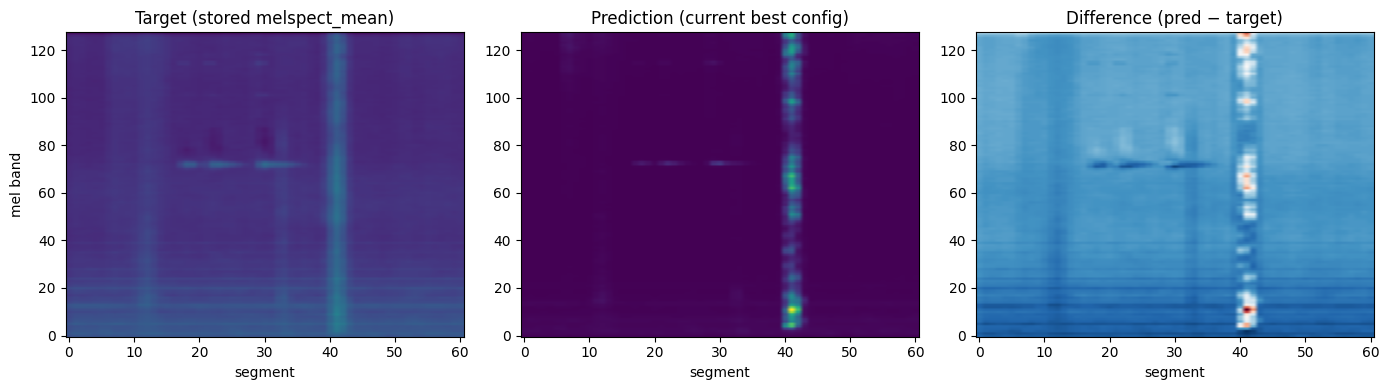


--- Audio loading sanity ---
  waveform dtype       : torch.float32
  waveform min/max     : -0.838440 / 0.883240
  waveform abs().mean(): 0.005083
  waveform RMS         : 0.026025


In [3]:
# ============================================================================
# CELL 1.6 — Diagnose where the mismatch comes from
# ============================================================================
import matplotlib.pyplot as plt

# --- 1.6.1 Print target stats (we missed this) -----------------------------
print("--- Target (stored melspect_mean) ---")
print(f"  shape  : {target.shape}")
print(f"  min    : {target.min():.6f}")
print(f"  max    : {target.max():.6f}")
print(f"  mean   : {target.mean():.6f}")
print(f"  std    : {target.std():.6f}")
print(f"  median : {np.median(target):.6f}")
print(f"  pct of vals == 0 : {(target == 0).mean()*100:.2f}%")
print(f"  pct of vals  < 0 : {(target  < 0).mean()*100:.2f}%")

# --- 1.6.2 Recompute prediction with the current 'best' config -------------
mel_best = T.MelSpectrogram(
    sample_rate=sr, n_fft=best["n_fft"], win_length=best["n_fft"],
    hop_length=best["hop_length"], f_min=best["f_min"], f_max=best["f_max"],
    n_mels=n_mels, power=best["power"], mel_scale=best["mel_scale"],
    norm=best["norm"],
)
with torch.no_grad():
    frames = mel_best(waveform).squeeze(0).numpy()       # [n_mels, n_frames]
pred = aggregate_frames_to_segments(frames, sr, best["hop_length"],
                                    start_time, end_time)
n = min(pred.shape[0], target.shape[0])
pred, target_aligned = pred[:n], target[:n]

print("\n--- Prediction (best config so far) ---")
print(f"  shape  : {pred.shape}")
print(f"  min    : {pred.min():.6f}")
print(f"  max    : {pred.max():.6f}")
print(f"  mean   : {pred.mean():.6f}")
print(f"  std    : {pred.std():.6f}")

# --- 1.6.3 Are they at least correlated? -----------------------------------
# If correlation is high but MSE is bad: it's a SCALE/SHIFT problem (fixable).
# If correlation is low: it's a DIFFERENT FEATURE entirely.
flat_p, flat_t = pred.flatten(), target_aligned.flatten()
pearson = float(np.corrcoef(flat_p, flat_t)[0, 1])
print(f"\n--- Correlation diagnostic ---")
print(f"  Pearson(pred, target) over all values : {pearson:.4f}")

# Per-mel-band correlation: tells us if shape matches band-by-band.
band_corrs = [float(np.corrcoef(pred[:, b], target_aligned[:, b])[0, 1])
              if pred[:, b].std() > 0 and target_aligned[:, b].std() > 0
              else 0.0 for b in range(n_mels)]
print(f"  Mean per-band corr   : {np.mean(band_corrs):.4f}")
print(f"  Median per-band corr : {np.median(band_corrs):.4f}")
print(f"  Min per-band corr    : {min(band_corrs):.4f}")

# --- 1.6.4 Try simple alignment transforms ---------------------------------
# If high correlation → there's a closed-form transform from pred → target.
# Fit linear: target ≈ a * pred + b   (least squares, single scalar a, b).
from numpy.linalg import lstsq
A = np.stack([flat_p, np.ones_like(flat_p)], axis=1)
(a, b), *_ = lstsq(A, flat_t, rcond=None)
mse_linear = float(np.mean((a * flat_p + b - flat_t) ** 2))
print(f"\n--- Closed-form alignment attempts ---")
print(f"  Best linear fit: target ≈ {a:.4f}·pred + {b:.4f}")
print(f"    MSE after linear fit       : {mse_linear:.6f}")

# Per-band linear (each mel band gets its own scale + offset).
mse_perband = 0.0
for bi in range(n_mels):
    p_b, t_b = pred[:, bi], target_aligned[:, bi]
    Ab = np.stack([p_b, np.ones_like(p_b)], axis=1)
    (ab, bb), *_ = lstsq(Ab, t_b, rcond=None)
    mse_perband += float(np.mean((ab * p_b + bb - t_b) ** 2))
mse_perband /= n_mels
print(f"    MSE after per-band linear  : {mse_perband:.6f}")

# Z-score normalization (mean-zero, unit-std) on both, then compare.
def z(x): return (x - x.mean()) / (x.std() + 1e-12)
mse_z = float(np.mean((z(flat_p) - z(flat_t)) ** 2))
print(f"    MSE after global z-score   : {mse_z:.6f}  "
      f"(<0.05 → identical up to affine transform)")

# --- 1.6.5 Side-by-side preview --------------------------------------------
print(f"\n--- First segment, first 8 mel bands ---")
print("  band   pred           target         ratio")
for b in range(8):
    r = pred[0, b] / target_aligned[0, b] if target_aligned[0, b] != 0 else float("nan")
    print(f"  {b:3d}    {pred[0, b]:12.4f}   {target_aligned[0, b]:12.4f}   {r:7.3f}")

# --- 1.6.6 Visual comparison -----------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
vmax = max(pred.max(), target_aligned.max())
axes[0].imshow(target_aligned.T, aspect="auto", origin="lower", vmin=0, vmax=vmax)
axes[0].set_title("Target (stored melspect_mean)")
axes[0].set_xlabel("segment"); axes[0].set_ylabel("mel band")
axes[1].imshow(pred.T, aspect="auto", origin="lower", vmin=0, vmax=vmax)
axes[1].set_title("Prediction (current best config)")
axes[1].set_xlabel("segment")
axes[2].imshow((pred - target_aligned).T, aspect="auto", origin="lower", cmap="RdBu_r")
axes[2].set_title("Difference (pred − target)")
axes[2].set_xlabel("segment")
plt.tight_layout(); plt.show()

# --- 1.6.7 Audio loading sanity check --------------------------------------
# The pipeline may have loaded audio differently (peak-normalize, int16 scale, …)
print(f"\n--- Audio loading sanity ---")
print(f"  waveform dtype       : {waveform.dtype}")
print(f"  waveform min/max     : {waveform.min().item():.6f} / {waveform.max().item():.6f}")
print(f"  waveform abs().mean(): {waveform.abs().mean().item():.6f}")
print(f"  waveform RMS         : {(waveform**2).mean().sqrt().item():.6f}")

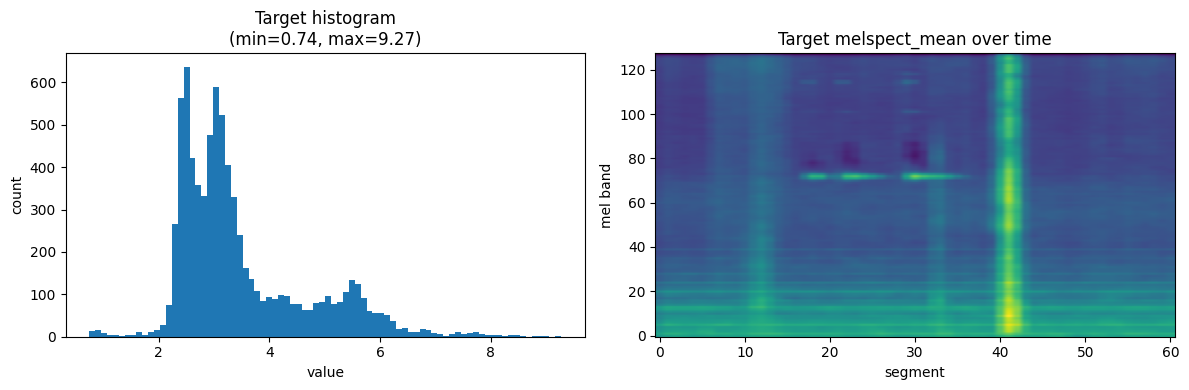

/opt/anaconda3/envs/mlpc2026/lib/python3.14/site-packages/torchaudio/functional/functional.py:581: UserWarning: At least one mel filterbank has all zero values. The value for `n_mels` (128) may be set too high. Or, the value for `n_freqs` (513) may be set too low.
  warnings.warn(
/opt/anaconda3/envs/mlpc2026/lib/python3.14/site-packages/torchaudio/functional/functional.py:581: UserWarning: At least one mel filterbank has all zero values. The value for `n_mels` (128) may be set too high. Or, the value for `n_freqs` (769) may be set too low.
  warnings.warn(


--- Best log1p(power_mel) config ---
  mse          = 11.312233924865723
  n_fft        = 4096
  hop_length   = 2048
  f_min        = 50.0
  f_max        = 16000.0
  mel_scale    = htk
  norm         = None
  center       = True
  RMSE / target_std : 2.8219

--- Best log1p(magnitude_mel) config ---
  mse          = 10.074312210083008
  n_fft        = 4096
  hop_length   = 2048
  f_min        = 50.0
  f_max        = 16000.0
  mel_scale    = htk
  norm         = None
  center       = True
  RMSE / target_std : 2.6630

--- Winner diagnostics (power=1.0) ---
  Pearson(pred, target) : 0.4733
  pred  range: [0.056, 3.753]  mean=0.487
  target range: [0.744, 9.274]  mean=3.481


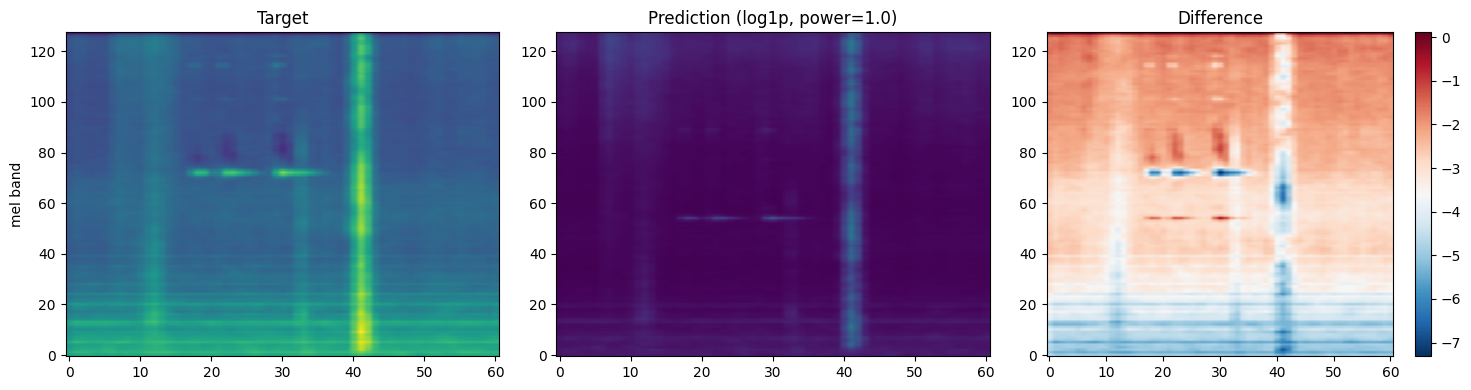

In [4]:
# ============================================================================
# CELL 1.7 — Test the log1p(power_mel) hypothesis directly, with viz
# ============================================================================
import matplotlib.pyplot as plt

# --- 1.7.1 Visual reality check on the target ------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(target.flatten(), bins=80)
axes[0].set_title(f"Target histogram\n(min={target.min():.2f}, max={target.max():.2f})")
axes[0].set_xlabel("value"); axes[0].set_ylabel("count")
axes[1].imshow(target.T, aspect="auto", origin="lower")
axes[1].set_title("Target melspect_mean over time")
axes[1].set_xlabel("segment"); axes[1].set_ylabel("mel band")
plt.tight_layout(); plt.show()

# --- 1.7.2 Exhaustive log1p(power_mel) sweep -------------------------------
# Hypothesis lock-in: power=2.0, log1p applied AT FRAME level, then mean.
# Vary only the STFT geometry and mel filterbank options.
hypotheses = []
for n_fft in [1024, 1536, 2048, 4096]:
    for hop in [n_fft // 4, n_fft // 2]:
        for f_min in [0.0, 20.0, 50.0]:
            for f_max in [sr / 2, 8000.0, 12000.0, 16000.0]:
                if f_max > sr / 2: continue
                for mel_scale in ["htk", "slaney"]:
                    for norm in [None, "slaney"]:
                        for center in [True, False]:
                            hypotheses.append(dict(
                                n_fft=n_fft, hop_length=hop, f_min=f_min,
                                f_max=f_max, mel_scale=mel_scale, norm=norm,
                                center=center,
                            ))

best3 = {"mse": float("inf")}
for p in hypotheses:
    mel = T.MelSpectrogram(
        sample_rate=sr, n_fft=p["n_fft"], win_length=p["n_fft"],
        hop_length=p["hop_length"], f_min=p["f_min"], f_max=p["f_max"],
        n_mels=128, power=2.0, mel_scale=p["mel_scale"], norm=p["norm"],
        center=p["center"],
    )
    with torch.no_grad():
        frames_pow = mel(waveform).squeeze(0)            # [n_mels, n_frames]
        frames_log = torch.log1p(frames_pow).numpy()     # log1p AT FRAME level
    pred = aggregate_frames_to_segments(frames_log, sr, p["hop_length"],
                                         start_time, end_time)
    n = min(pred.shape[0], target.shape[0])
    mse = float(np.mean((pred[:n] - target[:n]) ** 2))
    if mse < best3["mse"]:
        best3 = {"mse": mse, **p}

print("--- Best log1p(power_mel) config ---")
for k, v in best3.items():
    print(f"  {k:12s} = {v}")
print(f"  RMSE / target_std : {best3['mse']**0.5 / target.std():.4f}")

# --- 1.7.3 Also try magnitude (power=1) with log1p, just to be thorough ----
best3_mag = {"mse": float("inf")}
for p in hypotheses:
    mel = T.MelSpectrogram(
        sample_rate=sr, n_fft=p["n_fft"], win_length=p["n_fft"],
        hop_length=p["hop_length"], f_min=p["f_min"], f_max=p["f_max"],
        n_mels=128, power=1.0, mel_scale=p["mel_scale"], norm=p["norm"],
        center=p["center"],
    )
    with torch.no_grad():
        frames_mag = mel(waveform).squeeze(0)
        frames_log = torch.log1p(frames_mag).numpy()
    pred = aggregate_frames_to_segments(frames_log, sr, p["hop_length"],
                                         start_time, end_time)
    n = min(pred.shape[0], target.shape[0])
    mse = float(np.mean((pred[:n] - target[:n]) ** 2))
    if mse < best3_mag["mse"]:
        best3_mag = {"mse": mse, **p}
print("\n--- Best log1p(magnitude_mel) config ---")
for k, v in best3_mag.items():
    print(f"  {k:12s} = {v}")
print(f"  RMSE / target_std : {best3_mag['mse']**0.5 / target.std():.4f}")

# --- 1.7.4 Side-by-side visual of best result ------------------------------
winner = best3 if best3["mse"] < best3_mag["mse"] else best3_mag
power_used = 2.0 if winner is best3 else 1.0
mel = T.MelSpectrogram(
    sample_rate=sr, n_fft=winner["n_fft"], win_length=winner["n_fft"],
    hop_length=winner["hop_length"], f_min=winner["f_min"], f_max=winner["f_max"],
    n_mels=128, power=power_used, mel_scale=winner["mel_scale"],
    norm=winner["norm"], center=winner["center"],
)
with torch.no_grad():
    frames_log = torch.log1p(mel(waveform).squeeze(0)).numpy()
pred = aggregate_frames_to_segments(frames_log, sr, winner["hop_length"],
                                     start_time, end_time)
n = min(pred.shape[0], target.shape[0])
pred, tgt = pred[:n], target[:n]

pearson = float(np.corrcoef(pred.flatten(), tgt.flatten())[0, 1])
print(f"\n--- Winner diagnostics (power={power_used}) ---")
print(f"  Pearson(pred, target) : {pearson:.4f}")
print(f"  pred  range: [{pred.min():.3f}, {pred.max():.3f}]  mean={pred.mean():.3f}")
print(f"  target range: [{tgt.min():.3f}, {tgt.max():.3f}]  mean={tgt.mean():.3f}")

vmin, vmax = min(pred.min(), tgt.min()), max(pred.max(), tgt.max())
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(tgt.T,  aspect="auto", origin="lower", vmin=vmin, vmax=vmax)
axes[0].set_title("Target"); axes[0].set_ylabel("mel band")
axes[1].imshow(pred.T, aspect="auto", origin="lower", vmin=vmin, vmax=vmax)
axes[1].set_title(f"Prediction (log1p, power={power_used})")
im = axes[2].imshow((pred - tgt).T, aspect="auto", origin="lower", cmap="RdBu_r")
axes[2].set_title("Difference"); plt.colorbar(im, ax=axes[2])
plt.tight_layout(); plt.show()